# 04d - Clustering: perfis de mutuários

Agrupar os mutuários pelo perfil de crédito no momento do pedido, sem alvo: o algoritmo junta empréstimos parecidos e a leitura dos grupos é feita depois. O enunciado dá este exemplo: *"borrower clustering (FICO, DTI, credit age, utilization)"*.

São dois algoritmos, o k-means e a mistura de gaussianas (GMM), com o número de grupos a variar de 2 a 10. As medidas de avaliação estão em `src/lending/clustering.py` (`ClusterEvaluator`) e as variáveis e o pré-processamento na classe `BorrowerProfiles` do mesmo módulo.

| Requisito do enunciado | Onde |
|---|---|
| *"Apply at least two clustering algorithms"* | k-means e GMM |
| *"Vary their relevant hyperparameters, including the number of clusters"* | k de 2 a 10; no GMM também o tipo de covariância |
| *"Describe the resulting groups and assess their stability and interpretability"* | Perfis dos grupos e ARI entre sementes e entre amostras |
| *"For clustering, use appropriate internal measures alongside substantive interpretation"* | Cotovelo, silhueta, Davies-Bouldin e Dunn (implementado por nós) |

**Antes de correr:** `01_preprocessamento.ipynb` (gera `aceites_dev.pkl`).

**Ficheiros e tempo de execução.** Cada configuração (algoritmo e número de grupos) é ajustada uma vez e guardada pelo `ClusterGrid`: as medidas em `reports/results/clustering_borrowers.csv` (entra no Git) e o grupo de cada empréstimo em `data/processed/clustering/borrowers/` (fora do Git). Nas execuções seguintes, as configurações já guardadas são lidas em vez de recalculadas. Com `RECALCULAR = True` (no setup), apaga-se tudo e volta-se a calcular do zero.

In [1]:
# Setup: imports e caminhos do projeto
import json
import sys
from pathlib import Path

# Importar o pacote do projeto.
try:
    import lending
except ModuleNotFoundError:
    for parent in [Path.cwd(), *Path.cwd().parents]:
        if (parent / "src" / "lending").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import lending

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

from lending import config
from lending.clustering import (PROFILE_LABELS, RESULTS_DIR, BorrowerProfiles, ClusterGrid, cached_csv,
                                disjoint_halves, gmm_spec, group_outcomes, group_profiles, kmeans_spec,
                                match_labels, matched_share, outcome_observed, seed_stability,
                                subset_stability)
from lending.plot_style import CATEGORICAL, DIVERGING_CMAP, SEQUENTIAL_CMAP, apply_style
from lending.storage import PickleStore

apply_style()
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

# True: apaga os resultados guardados das grelhas e volta a calcular tudo (demora minutos)
RECALCULAR = False

## 1. Dados e variáveis

**Coorte.** São os 466 124 empréstimos aceites de 2007-06 a 2014-12 (a coorte do clustering da Parte 1, sem filtros além da limpeza). Ao contrário da classificação, não é preciso conhecer o desfecho, por isso entram também os empréstimos ainda ativos (`Current`). O teste de 2015 nunca é usado: o clustering é descritivo e não tem avaliação final.

**Variáveis do ajuste** (perfil no momento do pedido):

| Variável | O que mede | Porquê |
|---|---|---|
| `fico_range_low` | Pontuação de crédito | Exemplo do enunciado. O `fico_range_high` é sempre `low + 4`: as duas dariam o mesmo valor padronizado e o FICO contaria a dobrar |
| `dti` | Dívidas mensais / rendimento mensal (%) | Exemplo do enunciado |
| `revol_util` | % do limite rotativo em uso | "Utilização" do enunciado |
| `annual_inc` | Rendimento anual | Capacidade financeira |
| `loan_to_income` | Montante pedido / rendimento | Esforço do pedido |
| `revol_to_income` | Saldo rotativo / rendimento | Dívida de cartões face ao rendimento (o `revol_util` não o diz) |
| `open_acc_pct` | % das contas do historial ainda abertas | Crédito recente ou acumulado |
| `credit_history_years` | Anos desde a primeira linha de crédito até à concessão | "Credit age" do enunciado |

A antiguidade do crédito usa o `issue_d` como data de referência. Na tabela de elegibilidade da Fase 1 o `issue_d` estava ❌ no clustering; passou a ⚠️, só como referência desta feature (como já acontecia na classificação).

**Fora do ajuste:** as binárias `ever_delinquent` e `has_public_record` só descrevem os grupos. A taxa de juro, o grau e o desfecho também ficam de fora: são usados depois, para dar significado de negócio aos grupos, e não podem influenciar a sua formação.

In [2]:
data = PickleStore.load(config.ACCEPTED_DEV_PKL, expected_type=pd.DataFrame)
print(f"{len(data):,} empréstimos, {data['issue_d'].min():%Y-%m} a {data['issue_d'].max():%Y-%m}")

profiles = BorrowerProfiles()
original = profiles.table(data)   # unidades originais, antes do pré-processamento

summary = pd.DataFrame({
    "em falta": original.isna().sum(),
    "em falta (%)": (100 * original.isna().mean()).round(3),
    "mínimo": original.min(),
    "p0,5": original.quantile(0.005),
    "mediana": original.median(),
    "p99,5": original.quantile(0.995),
    "máximo": original.max(),
    "assimetria": original.skew(),
}).rename(index=PROFILE_LABELS)
summary.round(2)

466,124 empréstimos, 2007-06 a 2014-12


,em falta,em falta (%),mínimo,"p0,5",mediana,"p99,5",máximo,assimetria
FICO,0,0.00,610.0,660.00,690.00,805.00,845.00,1.24
DTI (%),0,0.00,0.0,0.93,16.87,36.47,39.99,0.19
Utilização rotativa (%),340,0.07,0.0,0.10,57.60,99.20,892.30,-0.16
Rendimento anual (USD),4,0.00,1896.0,15000.00,63000.00,300000.00,7500000.00,29.57
Montante / rendimento,4,0.00,0.0,0.02,0.21,0.49,1.34,0.39
Saldo rotativo / rendimento,4,0.00,0.0,0.00,0.19,1.07,7.96,4.20
Contas abertas (%),31,0.01,0.0,14.71,46.43,100.00,100.00,0.56
Antiguidade do crédito (anos),29,0.01,0.5,3.50,14.50,42.00,70.17,1.07
Já teve atrasos,29,0.01,0.0,0.00,0.00,1.00,1.00,0.15
Tem registo público,29,0.01,0.0,0.00,0.00,1.00,1.00,2.18


**Leitura.**

- **Quase sem valores em falta.** O máximo é o `revol_util`, com 340 (0,07%). As 29 linhas sem antiguidade, atrasos e registos públicos são as mesmas: empréstimos de 2007 sem nenhum dado do *bureau*. A `open_acc_pct` tem mais 2, os casos impossíveis de 2007 (mais contas abertas do que no total).
- **Caudas longas.** O rendimento chega a 7,5 milhões (assimetria 29,6) e o saldo rotativo a 7,96 vezes o rendimento (assimetria 4,2). A utilização rotativa chega a 892%. É isto que o log e o *clipping* tratam.
- **FICO de 610 a 845**, mediana 690. Os 488 empréstimos abaixo de 660 são quase todos (99,6%) *"Does not meet the credit policy"* de 2007–2008.
- **Binárias (só para descrever):** 46,2% dos mutuários já tiveram algum atraso e 13,2% têm pelo menos um registo público.

### Pré-processamento

Os mesmos passos do pipeline da Parte 1, aplicados às 8 variáveis (`BorrowerProfiles.pipeline()`):

1. **Logaritmo no rendimento**, `log(1 + x)`: o rendimento tem uma cauda longa à direita (até 7,5 milhões). Sem o log, os rendimentos altos ficavam muito longe de todos os outros e formavam um grupo só por isso.
2. **Clipping** aos percentis 0,5 e 99,5: os valores mais extremos (ex.: `revol_util` de 892%) passam a ser iguais ao percentil.
3. **Imputação pela mediana**, **sem indicador de "em falta"**. No pipeline da Parte 1, cada coluna com falta ganha uma coluna 0/1. No clustering isso não serve: com 340 em falta (0,07%), o indicador padronizado vale cerca de 37 nessas linhas, uma distância enorme que criaria um grupo "dos que têm o `revol_util` em falta". Com tão poucas faltas, a mediana não muda a forma dos dados.
4. **Padronização** (média 0, desvio 1): a distância euclidiana soma diferenças ao quadrado, por isso sem padronizar o rendimento (dezenas de milhares) esmagava o FICO (centenas) e o DTI (dezenas).

O ajuste é feito em todos os empréstimos do clustering. Não há fuga de informação porque não há conjunto de teste: o clustering descreve estes empréstimos e não é avaliado noutros.

Matriz do clustering: 466,124 x 8, valores em falta: 0


,assimetria antes,assimetria depois,média,desvio
FICO,1.24,1.19,-0.0,1.0
DTI (%),0.19,0.18,-0.0,1.0
Utilização rotativa (%),-0.16,-0.27,-0.0,1.0
Rendimento anual (USD),29.57,0.11,-0.0,1.0
Montante / rendimento,0.39,0.37,0.0,1.0
Saldo rotativo / rendimento,4.20,1.58,0.0,1.0
Contas abertas (%),0.56,0.57,0.0,1.0
Antiguidade do crédito (anos),1.07,0.98,0.0,1.0


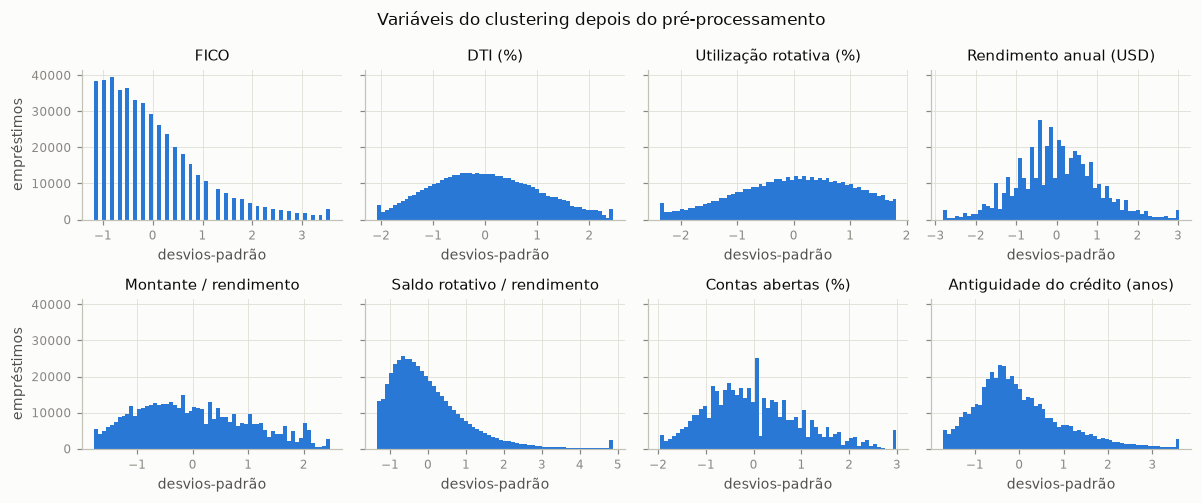

In [3]:
pipeline = profiles.pipeline()
X = pipeline.fit_transform(data[profiles.source_columns()])
print(f"Matriz do clustering: {X.shape[0]:,} x {X.shape[1]}, valores em falta: {int(X.isna().sum().sum())}")

check = pd.DataFrame({
    "assimetria antes": original[profiles.features].skew(),
    "assimetria depois": X.skew(),
    "média": X.mean(),
    "desvio": X.std(ddof=0),
}).rename(index=PROFILE_LABELS)
display(check.round(2))

fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharey=True)
for ax, column in zip(axes.ravel(), profiles.features):
    ax.hist(X[column], bins=60, color=CATEGORICAL[0])
    ax.set_title(PROFILE_LABELS[column])
    ax.set_xlabel("desvios-padrão")
for ax in axes[:, 0]:
    ax.set_ylabel("empréstimos")
fig.suptitle("Variáveis do clustering depois do pré-processamento")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_variaveis.png")
plt.show()

**Leitura.**

- A matriz final não tem valores em falta, e todas as colunas têm média 0 e desvio 1: as 8 variáveis pesam o mesmo na distância.
- **O log resolveu o rendimento:** a assimetria passou de 29,6 para 0,1.
- **O saldo rotativo / rendimento continua com cauda à direita** (assimetria 4,2 → 1,6). A barra isolada a 4,9 desvios são os 2 331 empréstimos (0,5%) presos no limite do *clipping*, com saldo rotativo acima de 1,07 vezes o rendimento. Se aparecer um grupo pequeno só com estes empréstimos, é por causa desta cauda; a coluna `smallest_cluster_pct` das grelhas serve para o detetar. Não se aplicou log a este rácio: `log(1 + x)` quase não muda valores abaixo de 1 (a assimetria só desceria para 1,05) e o *clipping* já limita o extremo.
- **O FICO é discreto** (passos de 5 pontos) e concentrado entre 660 e 720, com cauda à direita.
- As barras nos extremos de quase todas as variáveis são o *clipping*: os 0,5% de cada lado ficam acumulados no limite. Os "pentes" no rendimento vêm de valores redondos declarados (50 000, 60 000 USD).

### Correlações

Na distância euclidiana, duas variáveis muito correlacionadas medem quase a mesma coisa e essa dimensão do perfil conta a dobrar. Uma correlação de Spearman (ordens) acima de 0,8 seria razão para tirar uma das duas.

Maior |rho| entre duas variáveis: 0.41 (Montante / rendimento / Saldo rotativo / rendimento)


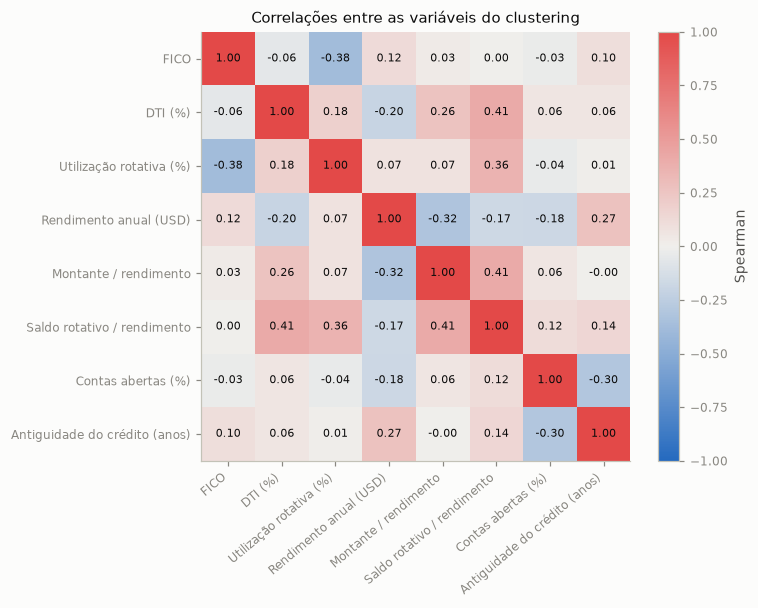

In [4]:
corr = X.corr(method="spearman").rename(index=PROFILE_LABELS, columns=PROFILE_LABELS)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(f"Maior |rho| entre duas variáveis: {upper.abs().max():.2f} "
      f"({upper.abs().idxmax()[0]} / {upper.abs().idxmax()[1]})")

fig, ax = plt.subplots(figsize=(7, 5.6))
image = ax.imshow(corr, cmap=DIVERGING_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Spearman")
ax.set_title("Correlações entre as variáveis do clustering")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_correlacoes.png")
plt.show()

**Leitura.**

- A maior correlação é 0,41 (montante / rendimento com saldo rotativo / rendimento, e DTI com saldo rotativo / rendimento). Nenhum par passa de 0,8, por isso as 8 variáveis ficam: cada uma acrescenta informação e nenhuma dimensão do perfil conta a dobrar.
- FICO e utilização rotativa: -0,38. É o esperado, porque a utilização do crédito entra no cálculo do FICO.
- Rendimento e montante / rendimento: -0,32, porque o rendimento é o denominador.
- Contas abertas (%) e antiguidade: -0,30. Quem tem um historial longo acumulou contas já fechadas.
- Com correlações tão fracas, não há razão para reduzir a dimensão (PCA) antes do clustering. A PCA fica só para desenhar os grupos.

### Composição no tempo

O clustering junta oito anos de empréstimos. Se a população mudou muito, os grupos podem refletir os anos em vez de perfis de mutuário.

In [5]:
year = data["issue_d"].dt.year.rename("ano")
by_year = original[profiles.features].groupby(year).median().rename(columns=PROFILE_LABELS)
by_year.insert(0, "% dos empréstimos", (100 * year.value_counts(normalize=True).sort_index()).round(1))
by_year.insert(0, "empréstimos", year.value_counts().sort_index())
by_year.round(2)

,empréstimos,% dos empréstimos,FICO,DTI (%),Utilização rotativa (%),Rendimento anual (USD),Montante / rendimento,Saldo rotativo / rendimento,Contas abertas (%),Antiguidade do crédito (anos)
ano,,,,,,,,,,
2007,603,0.1,680.0,10.00,48.1,50000.0,0.14,0.11,58.33,8.17
2008,2388,0.5,690.0,13.10,49.5,52529.5,0.14,0.18,50.00,11.00
2009,5280,1.1,710.0,12.60,44.4,57000.0,0.15,0.16,46.43,11.58
2010,12532,2.7,710.0,13.24,48.8,57996.0,0.16,0.15,43.95,12.33
2011,21709,4.7,710.0,13.92,51.5,60000.0,0.17,0.16,43.59,12.92
2012,53334,11.4,695.0,16.48,61.0,60000.0,0.20,0.20,47.06,13.33
2013,134767,28.9,690.0,16.89,60.3,64000.0,0.21,0.21,46.67,14.50
2014,235511,50.5,685.0,17.62,56.3,65000.0,0.21,0.19,46.67,15.17


**Leitura.**

- **2013 e 2014 têm 79,4% dos empréstimos** (só 2014 tem 50,5%), e 2007–2011 juntos têm 9,1%. Os grupos vão descrever sobretudo os mutuários de 2013–2014. Não se pondera nem se reamostra por ano: o objetivo é descrever os mutuários que a LendingClub financiou, e esses são, na maioria, dos últimos anos.
- **A população mudou:** o DTI mediano subiu de 10 (2007) para 17,6 (2014), a utilização rotativa passou de 44–52% (até 2011) para 56–61% (a partir de 2012) e a antiguidade do crédito de 8 para 15 anos. O FICO mediano subiu para 710 em 2009–2011 e voltou a descer para 685 em 2014.
- **Consequência:** um grupo pode juntar sobretudo empréstimos de um período (ex.: DTI baixo e historial curto, típico dos primeiros anos) em vez de um tipo de mutuário. Para o verificar, cada grupo vai ter a sua distribuição por ano e a estabilidade compara grupos ajustados em 2007–2012 e em 2013–2014. Isto responde ao pedido do enunciado de discutir a mudança temporal (*"temporal change"*).

## 2. k-means

**Como funciona** (algoritmo de Lloyd):

1. Escolhe k centros iniciais com o k-means++, que espalha os centros: cada novo centro tende a ficar longe dos anteriores.
2. Atribui cada empréstimo ao centro mais próximo (distância euclidiana).
3. Move cada centro para a média dos empréstimos que lhe ficaram atribuídos.
4. Repete 2 e 3 até os grupos deixarem de mudar.

Cada iteração faz descer a WSS (soma das distâncias ao quadrado de cada ponto ao seu centro), por isso o algoritmo converge, mas para um mínimo local que depende do início. Com `n_init=10` corre 10 inícios diferentes e fica o de menor WSS. O k-means supõe grupos "redondos" e de tamanho parecido, porque só olha para a distância ao centro.

**Grelha:** k de 2 a 10, nos 466 124 empréstimos, `n_init=10`, semente 42 (`kmeans_spec()`).

**Como ler as medidas** (calculadas pelo `ClusterEvaluator` nos mesmos pontos para todos os k):

| Medida | Melhor | Nota |
|---|---|---|
| WSS (cotovelo) | O k a partir do qual a descida deixa de compensar | Desce sempre com k, por isso não se escolhe o mínimo |
| Silhueta | Mais alta (máximo 1) | Amostra de 20 000 pontos |
| Davies-Bouldin | Mais baixo (mínimo 0) | Todos os pontos |
| Dunn | Mais alto | Amostra de 5 000 pontos; medida de pior caso |
| Grupo mais pequeno (%) | - | Deteta grupos minúsculos feitos de valores extremos |

In [6]:
grid = ClusterGrid("borrowers")
results = grid.run(X, [kmeans_spec()], recompute=RECALCULAR)

kmeans = results[results["model"] == "k-means"].copy()
kmeans["k"] = kmeans["params"].map(lambda p: json.loads(p)["n_clusters"])
kmeans = kmeans.sort_values("k").set_index("k")
# Quanto desce a WSS em relação ao k anterior (ajuda a ler o cotovelo)
kmeans["descida da WSS (%)"] = 100 * (1 - kmeans["wss"] / kmeans["wss"].shift())

kmeans_table = kmeans[["wss", "descida da WSS (%)", "silhouette", "davies_bouldin", "dunn",
                       "smallest_cluster_pct", "n_iter", "fit_seconds"]].rename(columns={
    "wss": "WSS", "silhouette": "silhueta", "davies_bouldin": "Davies-Bouldin",
    "smallest_cluster_pct": "grupo mais pequeno (%)", "n_iter": "iterações",
    "fit_seconds": "tempo de ajuste (s)"})
kmeans_table.round({"WSS": 0, "descida da WSS (%)": 1, "silhueta": 3, "Davies-Bouldin": 3,
                    "dunn": 4, "grupo mais pequeno (%)": 1, "tempo de ajuste (s)": 1})

,WSS,descida da WSS (%),silhueta,Davies-Bouldin,dunn,grupo mais pequeno (%),iterações,tempo de ajuste (s)
k,,,,,,,,
2,3123246.0,NaN,0.151,2.166,0.0505,48.9,13,0.9
3,2781551.0,10.9,0.145,1.983,0.0450,20.7,15,1.3
4,2506657.0,9.9,0.142,1.783,0.0587,16.2,13,1.6
5,2365442.0,5.6,0.133,1.892,0.0421,12.6,28,3.6
6,2248870.0,4.9,0.125,1.883,0.0550,11.1,42,3.1
7,2150184.0,4.4,0.118,1.888,0.0364,8.7,79,4.4
8,2065886.0,3.9,0.114,1.822,0.0368,6.5,121,6.0
9,1997384.0,3.3,0.113,1.789,0.0363,6.4,43,4.7
10,1936017.0,3.1,0.113,1.768,0.0381,6.1,130,5.8


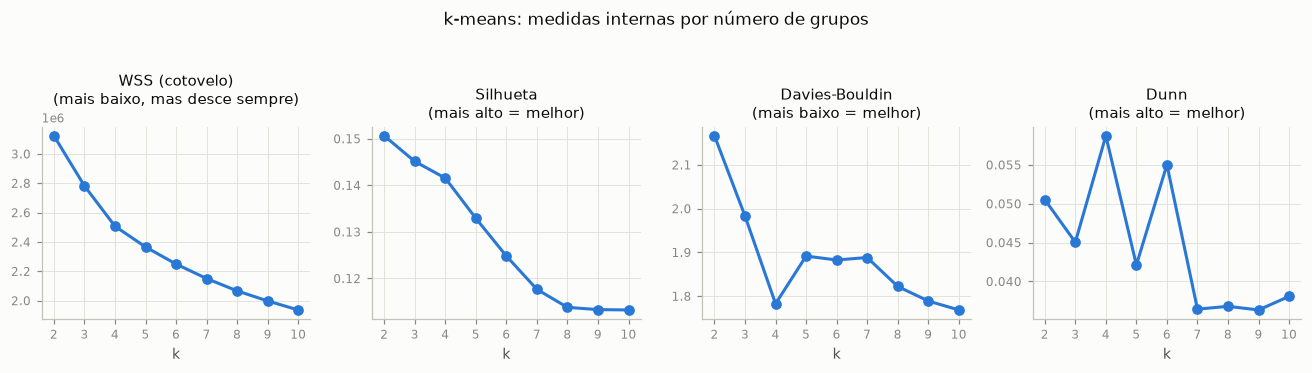

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
panels = [("wss", "WSS (cotovelo)", "mais baixo, mas desce sempre"),
          ("silhouette", "Silhueta", "mais alto = melhor"),
          ("davies_bouldin", "Davies-Bouldin", "mais baixo = melhor"),
          ("dunn", "Dunn", "mais alto = melhor")]
for ax, (column, title, note) in zip(axes, panels):
    ax.plot(kmeans.index, kmeans[column], marker="o", color=CATEGORICAL[0])
    ax.set_title(f"{title}\n({note})")
    ax.set_xlabel("k")
    ax.set_xticks(kmeans.index)
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
fig.suptitle("k-means: medidas internas por número de grupos", y=1.04)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_kmeans.png", bbox_inches="tight")
plt.show()

Tamanho dos grupos de cada k (em % dos empréstimos, do maior para o mais pequeno). Um grupo muito pequeno pode ser só a cauda de uma variável e não um tipo de mutuário.

In [8]:
sizes = {}
for k, row in kmeans.iterrows():
    labels = grid.labels("k-means", row["config_id"])
    sizes[k] = sorted(100 * np.bincount(labels) / len(labels), reverse=True)
sizes = pd.DataFrame.from_dict(sizes, orient="index")
sizes.columns = [f"{i}.º" for i in range(1, sizes.shape[1] + 1)]
sizes.index.name = "k"
sizes.round(1).fillna("")

,1.º,2.º,3.º,4.º,5.º,6.º,7.º,8.º,9.º,10.º
k,,,,,,,,,,
2,51.1,48.9,,,,,,,,
3,41.1,38.2,20.7,,,,,,,
4,32.5,27.5,23.9,16.2,,,,,,
5,29.5,24.5,18.5,14.9,12.6,,,,,
6,24.1,22.8,17.2,13.6,11.2,11.1,,,,
7,21.2,19.1,15.6,14.6,11.2,9.6,8.7,,,
8,16.6,15.4,14.9,13.8,13.1,10.7,8.9,6.5,,
9,13.9,13.9,13.9,11.8,11.6,10.5,9.9,8.2,6.4,
10,13.2,12.8,12.3,11.4,11.2,9.0,8.7,7.8,7.5,6.1


**Leitura.**

- **Cotovelo em k = 4.** A WSS desce 10,9% de k = 2 para 3 e 9,9% de 3 para 4. A partir daí a descida cai para metade (5,6% de 4 para 5) e continua a diminuir (3% a 5% por cada grupo a mais): cada grupo depois do 4.º explica pouco mais.
- **O Davies-Bouldin e o Dunn também apontam para k = 4.** O Davies-Bouldin tem um mínimo local em k = 4 (1,78, contra 1,88-1,89 em k = 5 a 7; só volta a esse nível em k = 10) e o Dunn é máximo em k = 4 (0,059). O Dunn oscila (0,042 em k = 5, 0,055 em k = 6) porque depende de um único par de pontos e de um único diâmetro, por isso serve de apoio e não decide sozinho.
- **A silhueta prefere k = 2** (0,151) e desce sempre com k, mas a diferença até k = 4 é pequena (0,142). E k = 2 só divide os empréstimos ao meio (51% / 49%), o que descreve pouco.
- **A estrutura é fraca.** As silhuetas, de 0,11 a 0,15, ficam abaixo de 0,25, o valor abaixo do qual se considera que não há estrutura substancial (Kaufman e Rousseeuw). O Dunn de 0,04 a 0,06 diz o mesmo: há sempre empréstimos de grupos diferentes quase colados. Os perfis de crédito formam um contínuo, sem grupos naturalmente separados, e o k-means faz uma segmentação desse contínuo. Os grupos continuam a servir, mas lêem-se como regiões do espaço dos perfis, com fronteiras convencionais; o seu valor está na estabilidade e na interpretação (passos seguintes), não na separação.
- **Nenhum grupo minúsculo.** O mais pequeno tem 16,2% dos empréstimos em k = 4 e nunca menos de 6,1% (k = 10). A cauda do saldo rotativo / rendimento (2 331 empréstimos no limite do *clipping*) não formou um grupo próprio.
- **Tempo:** 1 a 6 s por ajuste nos 466 124 empréstimos e cerca de 5 s de avaliação por k (quase tudo na silhueta). As iterações sobem de 13 para 130 com k: com mais grupos, as fronteiras passam por zonas densas e os centros demoram mais a estabilizar.

**Candidato: k = 4.** A escolha final fica para depois do GMM e da estabilidade.

## 3. Mistura de gaussianas (GMM)

**Como funciona.** Supõe que os dados vêm de k distribuições normais multivariadas (as componentes), cada uma com a sua média, a sua matriz de covariância e o seu peso (a fração dos dados que lhe pertence). Ajusta-se com o algoritmo EM (*expectation-maximization*):

1. **E:** com os parâmetros atuais, calcula a probabilidade de cada empréstimo pertencer a cada componente.
2. **M:** reestima as médias, as covariâncias e os pesos como médias ponderadas por essas probabilidades.
3. Repete até a verosimilhança deixar de subir.

O EM começa nos centros de um k-means e, como o k-means, só garante um ótimo local: `n_init=3` corre 3 inícios e fica o de maior verosimilhança.

**Diferenças face ao k-means:**
- **atribuição suave:** cada empréstimo tem uma probabilidade por grupo, e o grupo final é o mais provável;
- **grupos elípticos e de tamanhos diferentes,** porque cada componente tem a sua covariância. O k-means é o caso limite de um GMM com covariâncias esféricas iguais e atribuição "dura".

**Grelha** (`gmm_spec()`): k de 2 a 10 x tipo de covariância.
- `full`: matriz completa, ou seja, elipses com qualquer orientação (as variáveis podem estar correlacionadas dentro do grupo). São 8 médias + 36 covariâncias por grupo.
- `diag`: só as variâncias, ou seja, elipses alinhadas com os eixos. São 8 médias + 8 variâncias por grupo.

O ajuste usa os 466 124 empréstimos. Num teste, o maior ajuste (`full`, k = 10) demorou cerca de 35 s, por isso não foi preciso a amostra de 100 000 que o plano previa.

**Medidas próprias do GMM:**
- **BIC** = -2 log L + p log n (L = verosimilhança, p = número de parâmetros, n = pontos). Premeia o ajuste e penaliza a complexidade; mais baixo = melhor. O AIC usa 2p em vez de p log n.
- **Certeza da atribuição:** média da probabilidade do grupo atribuído. Perto de 1, os grupos estão bem separados; perto de 1/k, a atribuição é quase ao acaso.

A silhueta, o Davies-Bouldin e o Dunn são calculados sobre o grupo mais provável, nos mesmos pontos que no k-means, por isso os dois algoritmos são diretamente comparáveis.

In [9]:
# O RECALCULAR já foi aplicado na secção 2 (apaga a grelha toda, incluindo o GMM)
results = grid.run(X, [gmm_spec()])

gmm = results[results["model"] == "GMM"].copy()
params = gmm["params"].map(json.loads)
gmm["k"] = params.map(lambda p: p["n_components"])
gmm["covariância"] = params.map(lambda p: p["covariance_type"])
gmm = gmm.sort_values(["covariância", "k"]).set_index(["covariância", "k"])

gmm_table = gmm[["wss", "silhouette", "davies_bouldin", "dunn", "bic", "mean_max_proba",
                 "smallest_cluster_pct", "n_iter", "converged", "fit_seconds"]].rename(columns={
    "wss": "WSS", "silhouette": "silhueta", "davies_bouldin": "Davies-Bouldin",
    "bic": "BIC", "mean_max_proba": "certeza", "smallest_cluster_pct": "grupo mais pequeno (%)",
    "n_iter": "iterações", "converged": "convergiu", "fit_seconds": "tempo de ajuste (s)"})
gmm_table.round({"WSS": 0, "silhueta": 3, "Davies-Bouldin": 3, "dunn": 4, "BIC": 0, "certeza": 3,
                 "grupo mais pequeno (%)": 1, "tempo de ajuste (s)": 1})

WSS  silhueta  Davies-Bouldin    dunn         BIC  \
covariância k                                                             
diag        2   3158907.0     0.141           2.247  0.0499  10189829.0   
            3   2903907.0     0.104           2.276  0.0391   9999601.0   
            4   2620467.0     0.108           2.034  0.0335   9855224.0   
            5   2482784.0     0.106           2.117  0.0336   9789811.0   
            6   2413629.0     0.086           2.194  0.0386   9732773.0   
            7   2343723.0     0.073           2.133  0.0485   9678079.0   
            8   2268673.0     0.065           2.085  0.0336   9654844.0   
            9   2223781.0     0.063           2.229  0.0305   9607243.0   
            10  2142157.0     0.068           2.191  0.0336   9584785.0   
full        2   3250950.0     0.118           2.467  0.0499   9812905.0   
            3   3037988.0     0.107           2.468  0.0314   9612665.0   
            4   2818670.0     0.087           2.235  0.0361   9535663.0   
            5   2725313.0     0.066           2.429  0.0460   9490280.0   
            6   2664324.0     0.053           2.503  0.0361   9447627.0   
            7   2584584.0     0.040           2.567  0.0444   9425898.0   
            8   2376500.0     0.060           2.276  0.0424   9424617.0   
            9   2388593.0     0.044           2.436  0.0279   9379045.0   
            10  2367031.0     0.034           2.388  0.0361   9358904.0   

                certeza  grupo mais pequeno (%)  iterações convergiu  \
covariância k                                                          
diag        2     0.896                    49.4          6      True   
            3     0.843                    30.5         15      True   
            4     0.830                    16.4         13      True   
            5     0.812                    12.4         11      True   
            6     0.789                    11.1         16      True   
            7     0.784                     8.4         30      True   
            8     0.760                     8.1         28      True   
            9     0.754                     7.3         51      True   
            10    0.744                     6.2         26      True   
full        2     0.857                    44.6         10      True   
            3     0.853                    18.9         33      True   
            4     0.804                    14.7         20      True   
            5     0.767                    13.2         24      True   
            6     0.750                    11.0         32      True   
            7     0.727                     7.9         41      True   
            8     0.721                     8.1         19      True   
            9     0.705                     7.0         31      True   
            10    0.687                     5.7         31      True   

                tempo de ajuste (s)  
covariância k                        
diag        2                   3.3  
            3                   7.4  
            4                   8.5  
            5                   8.3  
            6                  14.6  
            7                  25.4  
            8                  26.7  
            9                  34.1  
            10                 31.1  
full        2                   8.4  
            3                  21.4  
            4                  27.6  
            5                  38.5  
            6                  54.0  
            7                  67.8  
            8                  50.1  
            9                  69.8  
            10                 96.1

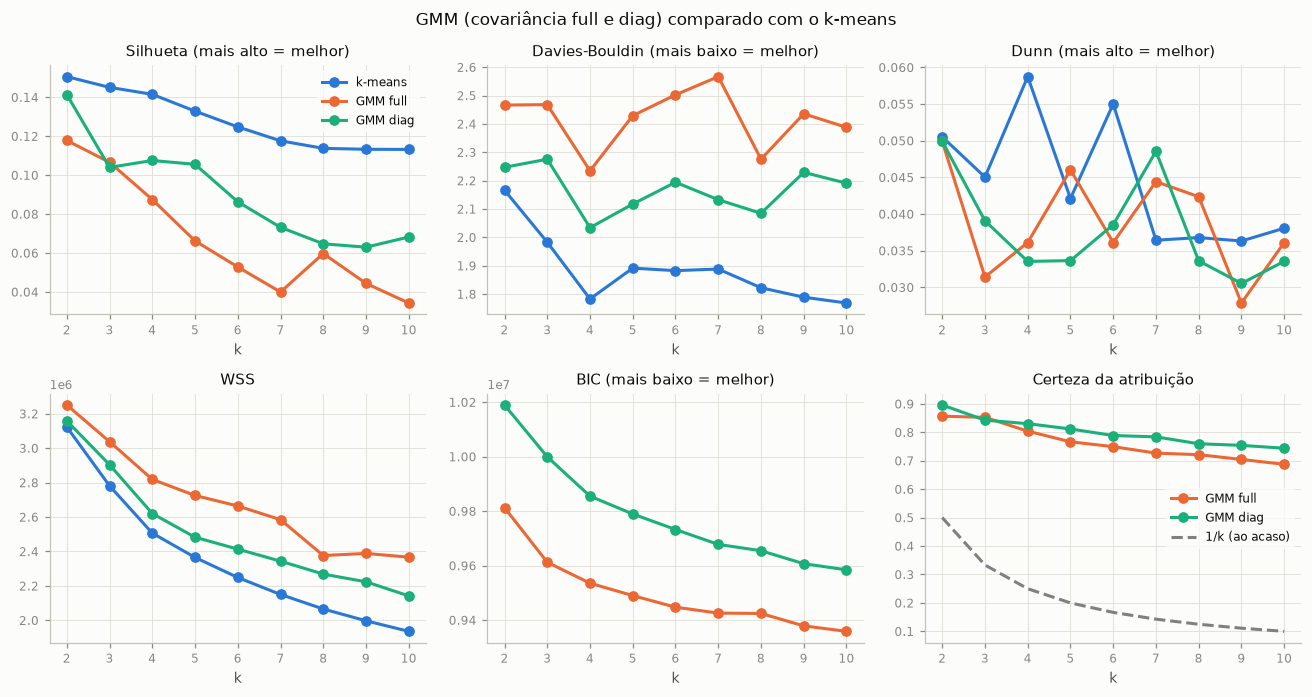

In [10]:
series = {"k-means": kmeans, "GMM full": gmm.loc["full"], "GMM diag": gmm.loc["diag"]}
panels = [("silhouette", "Silhueta (mais alto = melhor)"),
          ("davies_bouldin", "Davies-Bouldin (mais baixo = melhor)"),
          ("dunn", "Dunn (mais alto = melhor)"),
          ("wss", "WSS"),
          ("bic", "BIC (mais baixo = melhor)"),
          ("mean_max_proba", "Certeza da atribuição")]

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (column, title) in zip(axes.ravel(), panels):
    for (name, frame), color in zip(series.items(), CATEGORICAL):
        if column in frame and frame[column].notna().any():
            ax.plot(frame.index, frame[column], marker="o", color=color, label=name)
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.set_xticks(range(2, 11))
ks = np.arange(2, 11)
axes[1, 2].plot(ks, 1 / ks, linestyle="--", color="grey", label="1/k (ao acaso)")
axes[1, 2].legend()
axes[0, 0].legend()
for ax in (axes[1, 0], axes[1, 1]):
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
fig.suptitle("GMM (covariância full e diag) comparado com o k-means")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_gmm.png")
plt.show()

**Leitura.**

- **O BIC desce sempre com k**, nas duas covariâncias (de 9,81 para 9,36 milhões no `full`), por isso não escolhe o número de grupos. Com 466 124 pontos, a penalização p log n (log n ≈ 13 por parâmetro) é pequena face ao ganho de verosimilhança de cada componente nova. E os dados não são uma mistura de normais (FICO discreto, picos do *clipping*, caudas): cada componente nova "remenda" um desvio à normalidade. O que o BIC mostra com clareza é que o **`full` é sempre melhor do que o `diag`** (BIC cerca de 4% mais baixo em todos os k): as variáveis estão correlacionadas dentro dos grupos e as elipses inclinadas descrevem-nas melhor.
- **Nas medidas internas, o k-means ganha em todos os k** (silhueta 0,142 contra 0,108 no `diag` e 0,087 no `full`, em k = 4). Não quer dizer que o GMM seja pior: a silhueta, o Davies-Bouldin e a WSS usam a distância euclidiana e premeiam grupos compactos e "redondos", que é exatamente o que o k-means otimiza. O GMM `full` cria componentes largas e inclinadas, que se sobrepõem às outras, e por isso perde mais nestas medidas.
- **k = 4 volta a destacar-se:** o Davies-Bouldin tem um mínimo local em k = 4 nos três algoritmos (k-means 1,78, `diag` 2,03, `full` 2,24). No `diag`, a silhueta tem um patamar em k = 4-5 (0,108 e 0,106) depois da descida de k = 2 para 3.
- **O Dunn não distingue nada:** fica entre 0,03 e 0,05 em todos os casos e oscila sem padrão (é uma medida de pior caso, numa amostra).
- **Certeza da atribuição em k = 4:** 0,83 no `diag` e 0,80 no `full`, muito acima de 1/k = 0,25. Em média, cada empréstimo tem cerca de 80% de probabilidade no seu grupo: os grupos sobrepõem-se (coerente com a silhueta baixa), mas a maioria dos empréstimos tem um grupo claro. A certeza desce com k, porque grupos mais pequenos partilham mais fronteiras.
- **Sem problemas numéricos:** os 18 ajustes convergiram e o grupo mais pequeno nunca tem menos de 5,7%.
- **Tempo:** 3 a 96 s por ajuste (com 3 inícios cada), cerca de 10 minutos para a grelha inteira na primeira execução; nas seguintes, a grelha é lida do CSV.

**Para o passo seguinte:** k = 4 é o candidato nos dois algoritmos. Falta ver se o k-means e o GMM chegam aos **mesmos** grupos (ARI entre algoritmos) e escolher a configuração final.

## 4. Escolha de k e concordância entre os algoritmos

As medidas internas das secções 2 e 3 apontam para k = 4 nos dois algoritmos. Mas o mesmo **número** de grupos não garante os mesmos **grupos**. O k-means e o GMM partem de pressupostos diferentes (distâncias a centros contra densidades gaussianas). Se chegarem aos mesmos grupos, isso é sinal de que os grupos estão nos dados e não são um artefacto de um algoritmo.

Duas medidas de concordância entre dois agrupamentos dos mesmos 466 124 empréstimos:
- **ARI** (*adjusted Rand index*): proporção de pares de empréstimos em que os dois agrupamentos concordam (os dois juntos ou os dois separados), descontando a concordância esperada por acaso. 1 = iguais; cerca de 0 = acaso. Não depende dos nomes dos grupos.
- **Concordância (%)**: emparelham-se os grupos dos dois agrupamentos de forma a maximizar os empréstimos em comum (algoritmo húngaro, `match_labels`) e conta-se a percentagem de empréstimos que fica no grupo correspondente. É uma leitura mais direta: 75% = três em cada quatro empréstimos estão no "mesmo" grupo.

,ARI k-means / GMM diag,ARI k-means / GMM full,ARI GMM full / GMM diag,concordância k-means / GMM diag (%),concordância k-means / GMM full (%)
k,,,,,
2,0.668,0.435,0.589,90.853,82.976
3,0.205,0.188,0.406,56.419,59.820
4,0.454,0.239,0.411,75.007,59.879
5,0.536,0.266,0.373,78.031,61.124
6,0.428,0.209,0.299,70.510,47.168
7,0.267,0.221,0.202,47.173,50.722
8,0.309,0.355,0.312,58.009,62.658
9,0.260,0.226,0.323,49.595,45.093
10,0.304,0.248,0.363,56.849,50.962


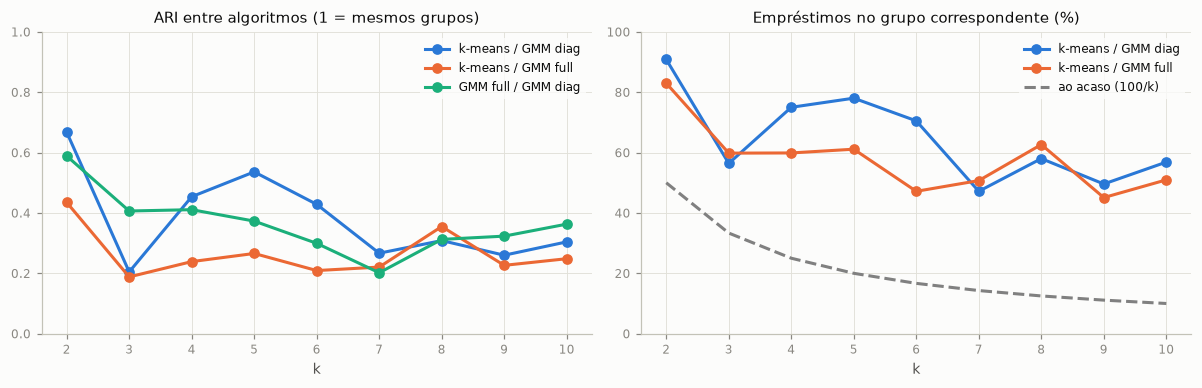

In [11]:
def labels_of(model, k, covariance=None):
    """Grupos guardados de uma configuração (k-means, ou GMM com a covariância indicada)."""
    table = kmeans if model == "k-means" else gmm.loc[covariance]
    return grid.labels(model, table.loc[k, "config_id"])


rows = []
for k in range(2, 11):
    km, full, diag = labels_of("k-means", k), labels_of("GMM", k, "full"), labels_of("GMM", k, "diag")
    rows.append({"k": k,
                 "ARI k-means / GMM diag": adjusted_rand_score(km, diag),
                 "ARI k-means / GMM full": adjusted_rand_score(km, full),
                 "ARI GMM full / GMM diag": adjusted_rand_score(full, diag),
                 "concordância k-means / GMM diag (%)": 100 * matched_share(km, diag),
                 "concordância k-means / GMM full (%)": 100 * matched_share(km, full)})
agreement = pd.DataFrame(rows).set_index("k")
display(agreement.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for column, color in zip(agreement.columns[:3], CATEGORICAL):
    axes[0].plot(agreement.index, agreement[column], marker="o", color=color, label=column[4:])
axes[0].set_title("ARI entre algoritmos (1 = mesmos grupos)")
axes[0].set_ylim(0, 1)
for column, color in zip(agreement.columns[3:], CATEGORICAL):
    axes[1].plot(agreement.index, agreement[column], marker="o", color=color, label=column[13:-4])
axes[1].plot(agreement.index, 100 / agreement.index, linestyle="--", color="grey", label="ao acaso (100/k)")
axes[1].set_title("Empréstimos no grupo correspondente (%)")
axes[1].set_ylim(0, 100)
for ax in axes:
    ax.set_xlabel("k")
    ax.set_xticks(agreement.index)
    ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_concordancia.png")
plt.show()

Em k = 4: para onde vão os empréstimos de cada grupo do k-means, depois de emparelhar os grupos do GMM (% de cada linha; a diagonal é a concordância). Ao lado, a mediana de algumas variáveis em cada grupo, para ver se os grupos emparelhados descrevem o mesmo tipo de mutuário.

In [12]:
km4, diag4, full4 = labels_of("k-means", 4), labels_of("GMM", 4, "diag"), labels_of("GMM", 4, "full")
diag4_matched, full4_matched = match_labels(km4, diag4), match_labels(km4, full4)

for name, matched in [("GMM diag", diag4_matched), ("GMM full", full4_matched)]:
    table = pd.crosstab(pd.Series(km4, name="grupo do k-means"), pd.Series(matched, name=f"grupo do {name}"),
                        normalize="index")
    display((100 * table).round(1))

key = ["fico_range_low", "revol_util", "dti", "annual_inc", "loan_to_income", "credit_history_years",
       "open_acc_pct"]
medians = pd.concat({name: original[key].groupby(labels).median()
                     for name, labels in [("k-means", km4), ("GMM diag", diag4_matched),
                                          ("GMM full", full4_matched)]}, names=["algoritmo", "grupo"])
medians.insert(0, "% dos empréstimos", pd.concat({name: pd.Series(labels).value_counts(normalize=True).sort_index() * 100
                                                for name, labels in [("k-means", km4), ("GMM diag", diag4_matched),
                                                                     ("GMM full", full4_matched)]}).to_numpy())
medians.swaplevel().sort_index().rename(columns=PROFILE_LABELS).round(2)

grupo do GMM diag,0,1,2,3
grupo do k-means,,,,
0,76.6,9.0,4.0,10.4
1,11.2,71.7,13.2,3.9
2,24.1,0.0,75.7,0.2
3,0.4,7.1,14.5,78.0


grupo do GMM full,0,1,2,3
grupo do k-means,,,,
0,77.2,9.1,2.8,11.0
1,33.2,52.4,13.1,1.3
2,46.2,2.7,48.8,2.3
3,2.2,7.3,22.2,68.3


% dos empréstimos   FICO  Utilização rotativa (%)  DTI (%)  \
grupo algoritmo                                                               
0     GMM diag               28.59  680.0                     63.1    18.72   
      GMM full               42.25  680.0                     66.0    18.54   
      k-means                23.85  680.0                     55.3    16.38   
1     GMM diag               26.57  680.0                     62.2    12.95   
      GMM full               21.11  680.0                     54.6    12.48   
      k-means                32.47  680.0                     64.8    14.00   
2     GMM diag               28.41  700.0                     63.8    21.91   
      GMM full               21.93  710.0                     62.0    19.93   
      k-means                27.51  690.0                     66.8    23.48   
3     GMM diag               16.43  730.0                     21.4    11.96   
      GMM full               14.71  735.0                     24.1    14.00   
      k-means                16.17  740.0                     24.3    12.64   

                 Rendimento anual (USD)  Montante / rendimento  \
grupo algoritmo                                                  
0     GMM diag                  48000.0                   0.25   
      GMM full                  56000.0                   0.24   
      k-means                   46000.0                   0.21   
1     GMM diag                  88140.0                   0.14   
      GMM full                  80000.0                   0.14   
      k-means                   85000.0                   0.15   
2     GMM diag                  61000.0                   0.29   
      GMM full                  65000.0                   0.26   
      k-means                   55000.0                   0.32   
3     GMM diag                  64871.0                   0.17   
      GMM full                  63000.0                   0.19   
      k-means                   70000.0                   0.18   

                 Antiguidade do crédito (anos)  Contas abertas (%)  
grupo algoritmo                                                     
0     GMM diag                           10.83               57.14  
      GMM full                           12.00               50.00  
      k-means                             9.58               65.22  
1     GMM diag                           16.25               40.62  
      GMM full                           18.42               40.00  
      k-means                            16.58               38.46  
2     GMM diag                           18.83               45.00  
      GMM full                           21.17               45.00  
      k-means                            16.50               45.00  
3     GMM diag                           14.00               45.45  
      GMM full                           13.42               47.06  
      k-means                            15.08               43.75

**Leitura.**

- **k = 2 concorda quase sempre** (91% com o GMM `diag`, ARI 0,67), mas com dois grupos o acaso já dá 50%: cortar a população ao meio é fácil de repetir e diz pouco.
- **k = 3 não se repete** (ARI cerca de 0,2 em todos os pares): cada algoritmo divide os dados em três de maneira diferente.
- **Em k = 4 e 5, o k-means e o GMM `diag` voltam a concordar:** 75% e 78% dos empréstimos ficam no grupo correspondente (ARI 0,45 e 0,54), contra 25% e 20% ao acaso. A partir de k = 6, a concordância cai para cerca de 50%: as divisões mais finas dependem do algoritmo, que é o que se espera ao cortar um contínuo.
- **Em k = 4, os grupos emparelhados descrevem os mesmos quatro tipos de mutuário** nos três modelos (medianas acima):
  - grupo 0: historial de crédito curto (cerca de 10 anos), rendimento baixo e muitas contas abertas;
  - grupo 1: rendimento alto (80 000-88 000 USD) e pouco esforço (montante / rendimento 0,14-0,15);
  - grupo 2: endividado (DTI 20-23%, montante / rendimento 0,26-0,32);
  - grupo 3: FICO alto (730-740) e utilização rotativa baixa (21-24%).

  Os números mudam um pouco de modelo para modelo, mas a ordem entre os grupos é a mesma em todas as variáveis.
- **O GMM `full` concorda menos** (60%, ARI 0,24). A sua componente 0 é um grupo largo com 42% dos empréstimos, que junta metade dos grupos 1 e 2 do k-means: as elipses inclinadas seguem as correlações e cortam o espaço de outra forma.

### Tabela de comparação do clustering

O enunciado pede uma tabela de comparação por tarefa, com *baselines*. No clustering, duas referências mostram o que valem as medidas internas:
- **Partição aleatória:** os grupos do k-means com k = 4 baralhados (mesmos tamanhos, nenhuma estrutura). É o "zero" das medidas.
- **Quartis do FICO:** a segmentação mais simples que um credor faria, com uma única variável. Se o clustering não fosse melhor do que isto, não acrescentava nada.

Todas as linhas são medidas pelo mesmo `ClusterEvaluator`, nos mesmos pontos. O ARI e a concordância são calculados em relação ao k-means com k = 4.

In [13]:
rng = np.random.default_rng(config.RANDOM_SEED)
fico_quartiles = pd.qcut(original["fico_range_low"], 4, labels=False, duplicates="drop").to_numpy()
candidates = [("Partição aleatória", rng.permutation(km4), None),
              ("Quartis do FICO", fico_quartiles, None),
              ("k-means", km4, kmeans.loc[4]),
              ("GMM diag", diag4, gmm.loc[("diag", 4)]),
              ("GMM full", full4, gmm.loc[("full", 4)])]

measures = ["n_clusters", "smallest_cluster_pct", "wss", "silhouette", "davies_bouldin", "dunn"]
rows = []
for name, labels, stored in candidates:
    # Os modelos já foram medidos na grelha; as referências são medidas agora, da mesma forma
    scores = grid.evaluator.evaluate(X, labels) if stored is None else stored[measures].to_dict()
    rows.append({"método": name, **scores,
                 "bic": np.nan if stored is None else stored.get("bic", np.nan),
                 "mean_max_proba": np.nan if stored is None else stored.get("mean_max_proba", np.nan),
                 "ari_kmeans": adjusted_rand_score(km4, labels),
                 "matched_kmeans_pct": 100 * matched_share(km4, labels),
                 "fit_seconds": np.nan if stored is None else stored["fit_seconds"]})
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS_DIR / "clustering_comparison.csv", index=False)

comparison.set_index("método").drop(columns="n_clusters").rename(columns={
    "smallest_cluster_pct": "grupo mais pequeno (%)", "wss": "WSS", "silhouette": "silhueta",
    "davies_bouldin": "Davies-Bouldin", "bic": "BIC", "mean_max_proba": "certeza",
    "ari_kmeans": "ARI com o k-means", "matched_kmeans_pct": "concordância com o k-means (%)",
    "fit_seconds": "tempo de ajuste (s)"}).round(3)

,grupo mais pequeno (%),WSS,silhueta,Davies-Bouldin,dunn,BIC,certeza,ARI com o k-means,concordância com o k-means (%),tempo de ajuste (s)
método,,,,,,,,,,
Partição aleatória,16.169,3728976.589,-0.002,813.843,0.026,NaN,NaN,0.000,26.417,NaN
Quartis do FICO,21.326,3242113.401,0.017,6.838,0.045,NaN,NaN,0.109,41.695,NaN
k-means,16.169,2506656.572,0.142,1.783,0.059,NaN,NaN,1.000,100.000,1.60
GMM diag,16.433,2620467.174,0.108,2.034,0.034,9855223.582,0.830,0.454,75.007,8.51
GMM full,14.712,2818669.520,0.087,2.235,0.036,9535663.070,0.804,0.239,59.879,27.55


**Leitura e escolha.**

- **As referências dão a escala das medidas.** A partição aleatória tem silhueta -0,002 e Davies-Bouldin 814: é o "zero". O k-means (0,142 e 1,78) está claramente acima, o que confirma que há alguma estrutura, ainda que fraca.
- **Os grupos não são escalões de FICO.** Os quartis do FICO têm silhueta 0,017 e Davies-Bouldin 6,8, e concordam pouco com o k-means (ARI 0,11; 42% contra 26% ao acaso). O clustering junta informação que o FICO sozinho não tem: rendimento, endividamento e historial.
- **O Dunn quase não separa estrutura de acaso:** 0,026 na partição aleatória, contra 0,034 e 0,036 nos GMM. Fica na tabela porque o plano o pede, mas não pesa na escolha.

**Escolha** (confirmada pela estabilidade, na secção seguinte):
- **k = 4 nos dois algoritmos.** É o cotovelo da WSS, o mínimo local do Davies-Bouldin nos três modelos, o máximo do Dunn no k-means e um dos dois k em que os algoritmos concordam (com k = 5 a concordância é parecida, 78%, mas as medidas internas são piores). A estabilidade desempatou a favor de k = 4 (secção 5).
- **Segmentação principal: k-means com k = 4.** Tem as melhores medidas internas. Os seus grupos são reencontrados por um algoritmo com outros pressupostos (75% com o GMM `diag`). É o mais simples de explicar e de aplicar a um pedido novo (o grupo é o centro mais próximo), e ajusta em 1,6 s.
- **GMM: `diag` com k = 4.** Concorda mais com o k-means, tem melhores medidas internas e maior certeza (0,83) do que o `full`. O `full` tem melhor BIC, mas cria um grupo largo (42%) que mistura dois tipos de mutuário.

## 5. Estabilidade

O enunciado pede para avaliar a estabilidade dos grupos (*"assess their stability"*). Um agrupamento é estável se quase não muda quando o procedimento se repete noutras condições. Três testes, todos comparados nos **mesmos** 466 124 empréstimos: cada modelo, ajustado de outra forma, dá um grupo a todos os empréstimos, e as atribuições comparam-se com o ARI e a concordância da secção 4.

1. **Sementes:** o mesmo procedimento, nos mesmos dados, com 5 sementes diferentes (10 pares). Mede quanto os grupos dependem do início aleatório.
2. **Metades disjuntas:** os empréstimos divididos ao acaso em duas metades sem nenhum empréstimo em comum, um modelo ajustado em cada metade, repetido em 5 divisões. Mede se outra amostra da mesma população daria os mesmos grupos. É o teste mais exigente dos dois.
3. **Períodos:** um modelo ajustado em 2007-2012 e outro em 2013-2014. Mede se os grupos sobrevivem à mudança da população no tempo (*"temporal change"*, fase 5).

O k-means corre para todos os k (de 2 a 10), o que dá uma curva de estabilidade por k, mais um critério para a escolha. O GMM `diag` corre só para k = 4 e 5, os dois candidatos da secção 4, porque cada ajuste é cerca de 5 vezes mais lento.

A primeira execução demora cerca de 10 minutos. Os resultados ficam em `reports/results/clustering_stability.csv` e são lidos nas execuções seguintes (salvo `RECALCULAR = True`).

In [14]:
Xn = X.to_numpy()
configs = ([(kmeans_spec(), {"n_clusters": k}, "k-means", k) for k in range(2, 11)]
           + [(gmm_spec(), {"n_components": k, "covariance_type": "diag"}, "GMM diag", k) for k in (4, 5)])


def stability_table():
    halves = disjoint_halves(len(Xn), n_splits=5)
    parts = []
    for spec, params, name, k in configs:
        seeds = seed_stability(spec, params, Xn).assign(teste="sementes")
        splits = pd.concat([subset_stability(spec, params, Xn, {"A": a, "B": b}).assign(teste="metades", divisao=i)
                            for i, (a, b) in enumerate(halves, start=1)])
        parts.append(pd.concat([seeds, splits]).assign(modelo=name, k=k))
    return pd.concat(parts, ignore_index=True)


stability = cached_csv(RESULTS_DIR / "clustering_stability.csv", stability_table, recompute=RECALCULAR)

summary = stability.groupby(["modelo", "k", "teste"])[["ari", "matched"]].agg(["mean", "min"]).unstack("teste")
summary.columns = [f"{'ARI' if m == 'ari' else 'concordância'} {t} ({'média' if a == 'mean' else 'mínimo'})"
                   for m, a, t in summary.columns]
summary = summary[[c for c in summary.columns if "sementes" in c] + [c for c in summary.columns if "metades" in c]]
summary.round(3)

ARI sementes (média)  ARI sementes (mínimo)  \
modelo   k                                                 
GMM diag 4                  0.999                  0.999   
         5                  0.973                  0.935   
k-means  2                  0.985                  0.973   
         3                  0.982                  0.974   
         4                  0.991                  0.984   
         5                  0.974                  0.955   
         6                  0.959                  0.933   
         7                  0.976                  0.956   
         8                  0.961                  0.934   
         9                  0.963                  0.948   
         10                 0.979                  0.966   

             concordância sementes (média)  concordância sementes (mínimo)  \
modelo   k                                                                   
GMM diag 4                           1.000                           1.000   
         5                           0.990                           0.975   
k-means  2                           0.996                           0.993   
         3                           0.994                           0.991   
         4                           0.997                           0.994   
         5                           0.989                           0.981   
         6                           0.983                           0.973   
         7                           0.990                           0.982   
         8                           0.984                           0.972   
         9                           0.984                           0.978   
         10                          0.990                           0.984   

             ARI metades (média)  ARI metades (mínimo)  \
modelo   k                                               
GMM diag 4                 0.971                 0.966   
         5                 0.947                 0.907   
k-means  2                 0.973                 0.965   
         3                 0.967                 0.959   
         4                 0.979                 0.970   
         5                 0.964                 0.951   
         6                 0.905                 0.876   
         7                 0.947                 0.939   
         8                 0.922                 0.852   
         9                 0.919                 0.858   
         10                0.934                 0.926   

             concordância metades (média)  concordância metades (mínimo)  
modelo   k                                                                
GMM diag 4                          0.989                          0.987  
         5                          0.979                          0.962  
k-means  2                          0.993                          0.991  
         3                          0.989                          0.986  
         4                          0.992                          0.989  
         5                          0.985                          0.979  
         6                          0.961                          0.948  
         7                          0.978                          0.974  
         8                          0.966                          0.936  
         9                          0.964                          0.936  
         10                         0.970                          0.966

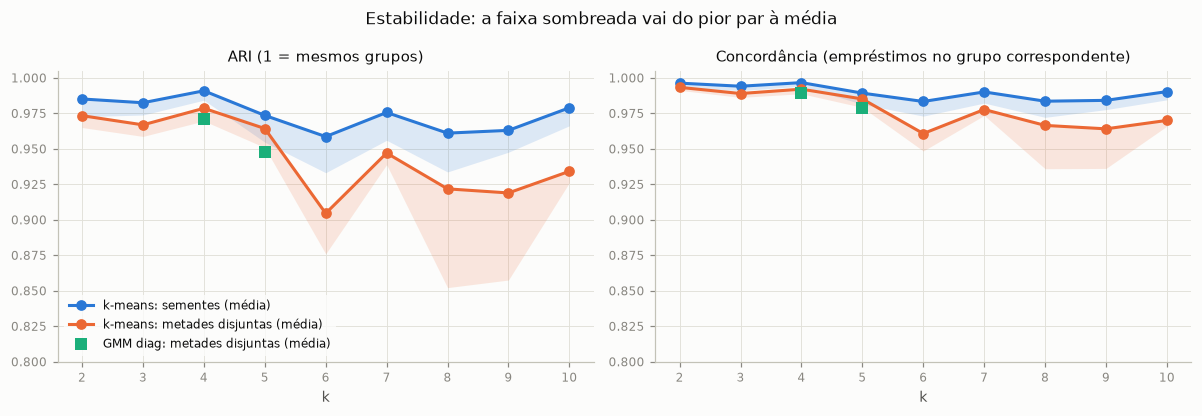

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
km_summary = stability[stability["modelo"] == "k-means"].groupby(["teste", "k"])[["ari", "matched"]]
for ax, column, title in [(axes[0], "ari", "ARI (1 = mesmos grupos)"),
                          (axes[1], "matched", "Concordância (empréstimos no grupo correspondente)")]:
    for (test, label), color in zip([("sementes", "k-means: sementes"), ("metades", "k-means: metades disjuntas")],
                                    CATEGORICAL):
        mean = km_summary.mean().loc[test, column]
        low = km_summary.min().loc[test, column]
        ax.plot(mean.index, mean, marker="o", color=color, label=f"{label} (média)")
        ax.fill_between(mean.index, low, mean, color=color, alpha=0.15)
    gmm_rows = stability[(stability["modelo"] == "GMM diag") & (stability["teste"] == "metades")]
    gmm_mean = gmm_rows.groupby("k")[column].mean()
    ax.scatter(gmm_mean.index, gmm_mean, marker="s", s=60, color=CATEGORICAL[2], zorder=3,
               label="GMM diag: metades disjuntas (média)")
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.set_xticks(range(2, 11))
    ax.set_ylim(0.8, 1.005)   # tudo acima de 0,85: o eixo começa em 0,8 para se verem as diferenças
axes[0].legend(loc="lower left")
fig.suptitle("Estabilidade: a faixa sombreada vai do pior par à média")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_estabilidade.png")
plt.show()

**Leitura.**

- **Os grupos reproduzem-se em todos os k.** O ARI fica acima de 0,85 em todos os testes, e a concordância acima de 93%. Com 466 124 empréstimos, os centros são estimados com muita precisão, por isso o procedimento dá quase sempre a mesma partição. Isto mostra que a segmentação é reprodutível, mas **não** que os grupos sejam "naturais": um k-means num contínuo também é estável quando há muitos dados. A estabilidade é uma condição necessária, não suficiente; a silhueta baixa da secção 2 continua válida.
- **k = 4 é o k mais estável nos dois algoritmos**, e isso desempata k = 4 e k = 5:
  - k-means: ARI 0,991 entre sementes (pior par 0,984) e 0,979 entre metades disjuntas (pior 0,970), os valores mais altos de toda a curva. Com k = 5 desce para 0,974 e 0,964, e a partir de k = 6 as metades caem para 0,90-0,95 (pior par 0,85 em k = 8): as divisões finas já dependem da amostra.
  - GMM `diag`: com k = 4, as sementes dão praticamente a mesma solução (ARI 0,999) e as metades 0,971; com k = 5, 0,973 e 0,947 (pior par 0,907).
- **Em concordância:** com k = 4, 99% dos empréstimos ficam no mesmo grupo quando o modelo é ajustado noutra metade dos dados.

### Estabilidade no tempo

Os empréstimos de 2007-2012 (20,6%) e de 2013-2014 (79,4%) vêm de populações diferentes (secção 1: o DTI, a utilização e a antiguidade do crédito subiram). Um modelo ajustado em cada período dá um grupo a todos os empréstimos, e compara-se como no teste das metades. Como referência, o ARI das metades disjuntas mostra quanto se perde só por mudar de amostra.

A seguir, a composição por ano dos grupos do k-means com k = 4 (o modelo da grelha, ajustado em todos os anos): se os grupos fossem só períodos, cada ano cairia quase todo num grupo.

In [16]:
years = year.to_numpy()
periods = {"2007-2012": np.flatnonzero(years <= 2012), "2013-2014": np.flatnonzero(years >= 2013)}


def period_table():
    parts = [subset_stability(spec, params, Xn, periods).assign(modelo=name, k=k)
             for spec, params, name, k in configs if k in (4, 5)]
    return pd.concat(parts, ignore_index=True)


by_period = cached_csv(RESULTS_DIR / "clustering_stability_periods.csv", period_table, recompute=RECALCULAR)
halves_mean = stability[stability["teste"] == "metades"].groupby(["modelo", "k"])[["ari", "matched"]].mean()
display(by_period.set_index(["modelo", "k"])[["ari", "matched"]]
        .join(halves_mean, rsuffix="_metades")
        .rename(columns={"ari": "ARI entre períodos", "matched": "concordância entre períodos",
                         "ari_metades": "ARI metades (referência)",
                         "matched_metades": "concordância metades (referência)"}).round(3))

composition = 100 * pd.crosstab(pd.Series(years, name="ano"), pd.Series(km4, name="grupo do k-means (k = 4)"),
                                normalize="index")
composition.round(1)

ARI entre períodos  concordância entre períodos  \
modelo   k                                                    
k-means  4               0.694                        0.873   
         5               0.695                        0.867   
GMM diag 4               0.525                        0.793   
         5               0.460                        0.730   

            ARI metades (referência)  concordância metades (referência)  
modelo   k                                                               
k-means  4                     0.979                              0.992  
         5                     0.964                              0.985  
GMM diag 4                     0.971                              0.989  
         5                     0.947                              0.979

grupo do k-means (k = 4),0,1,2,3
ano,,,,
2007,49.1,18.9,9.5,22.6
2008,37.0,24.7,14.0,24.3
2009,28.3,21.5,13.7,36.5
2010,26.0,25.3,13.7,34.9
2011,23.5,25.9,16.6,34.0
2012,26.7,28.4,26.3,18.6
2013,23.8,33.0,29.4,13.7
2014,22.8,34.4,29.0,13.8


**Leitura e escolha final.**

- **O tempo mexe nas fronteiras, mas os grupos sobrevivem.** Ajustado só em 2007-2012 ou só em 2013-2014, o k-means com k = 4 põe 87% dos empréstimos no grupo correspondente (ARI 0,69), contra 99% entre duas metades da mesma população (ARI 0,98). A diferença é o efeito da mudança temporal: cerca de 1 em cada 8 empréstimos muda de grupo porque as fronteiras se deslocam com a população. O GMM `diag` é mais sensível ao período (79%, ARI 0,53), porque as variâncias de cada grupo também mudam.
- **Os grupos não são períodos.** Todos os anos têm empréstimos dos quatro grupos. Muda a mistura, de forma coerente com a secção 1:
  - grupo 3 (FICO alto, utilização baixa): 34-36% em 2009-2011, 14% em 2013-2014. Depois da crise de 2008, a política de crédito foi mais apertada (FICO mediano de 710 nesses anos);
  - grupo 2 (endividado): 9,5% em 2007, 29% em 2013-2014, ao mesmo tempo que o DTI mediano subiu;
  - grupo 0 (historial curto): 49% em 2007, 23% em 2014; grupo 1 (rendimento alto): 19% em 2007, 34% em 2014.

  A mudança temporal aparece como uma mudança na carteira (mais mutuários endividados e menos mutuários "prime"), e não como grupos novos. É uma leitura útil para o relatório (*"temporal change"*) e para o plano de *deployment* (monitorizar a proporção de cada grupo).

**Escolha final:** k = 4, porque é o k mais estável nos dois algoritmos, além de ser o escolhido pelas medidas internas e pela concordância (secção 4). A segmentação principal é o **k-means com k = 4**, que também resiste melhor à mudança de período; o **GMM `diag` com k = 4** é a solução do segundo algoritmo. A interpretação dos grupos (perfis, taxa de juro e *default*) usa o k-means.

## 6. Interpretação dos grupos

A segmentação final é o **k-means com k = 4** (secções 4 e 5). Para a interpretar:

1. **Perfil em unidades originais:** tamanho de cada grupo, mediana de cada variável do ajuste e, nas binárias que ficaram fora do ajuste, a percentagem de empréstimos com 1 (`group_profiles`). A coluna "todos" é a referência.
2. **Mapa de calor das médias padronizadas:** cada célula diz quantos desvios-padrão a média do grupo está acima (vermelho) ou abaixo (azul) da média de todos os empréstimos. É a leitura mais rápida do que distingue cada grupo. As cores só indicam a direção: vermelho não quer dizer "pior".
3. **Projeção PCA colorida pelo grupo:** as 8 variáveis projetadas nas duas direções de maior variância, para ver como os grupos ocupam o espaço.

**Nomes dos grupos.** Os números do k-means são arbitrários. Cada grupo recebe o nome da variável em que é o extremo: o de maior FICO mediano, o de maior rendimento, o de historial de crédito mais curto e o de maior DTI. O código confirma que os quatro extremos caem em quatro grupos diferentes. Assim os nomes não dependem da numeração e continuam certos se a grelha for recalculada.

In [17]:
final = km4   # k-means com k = 4
medians_by_group = original[profiles.features].groupby(final).median()
GROUP_NAMES = {
    medians_by_group["fico_range_low"].idxmax(): "FICO alto",
    medians_by_group["annual_inc"].idxmax(): "Rendimento alto",
    medians_by_group["credit_history_years"].idxmin(): "Historial curto",
    medians_by_group["dti"].idxmax(): "Endividados",
}
assert len(GROUP_NAMES) == 4, "Cada nome tem de corresponder a um grupo diferente"
GROUP_ORDER = ["FICO alto", "Rendimento alto", "Historial curto", "Endividados"]
GROUP_COLORS = dict(zip(GROUP_ORDER, CATEGORICAL + ["#8e5bd6"]))
group = pd.Series(final, index=original.index).map(GROUP_NAMES)

profile = pd.concat([group_profiles(original, group).reindex(GROUP_ORDER),
                     group_profiles(original, np.full(len(original), "todos"))])
descriptor_labels = {c: f"{PROFILE_LABELS[c]} (%)" for c in profiles.descriptors}
profile.rename(columns={**PROFILE_LABELS, **descriptor_labels}).round(2).T

grupo,FICO alto,Rendimento alto,Historial curto,Endividados,todos
empréstimos,75367.00,151361.00,111185.00,128211.00,466124.00
% dos empréstimos,16.17,32.47,23.85,27.51,100.00
FICO,740.00,680.00,680.00,690.00,690.00
DTI (%),12.64,14.00,16.38,23.48,16.87
Utilização rotativa (%),24.30,64.80,55.30,66.80,57.60
Rendimento anual (USD),70000.00,85000.00,46000.00,55000.00,63000.00
Montante / rendimento,0.18,0.15,0.21,0.32,0.21
Saldo rotativo / rendimento,0.11,0.15,0.18,0.37,0.19
Contas abertas (%),43.75,38.46,65.22,45.00,46.43
Antiguidade do crédito (anos),15.08,16.58,9.58,16.50,14.50


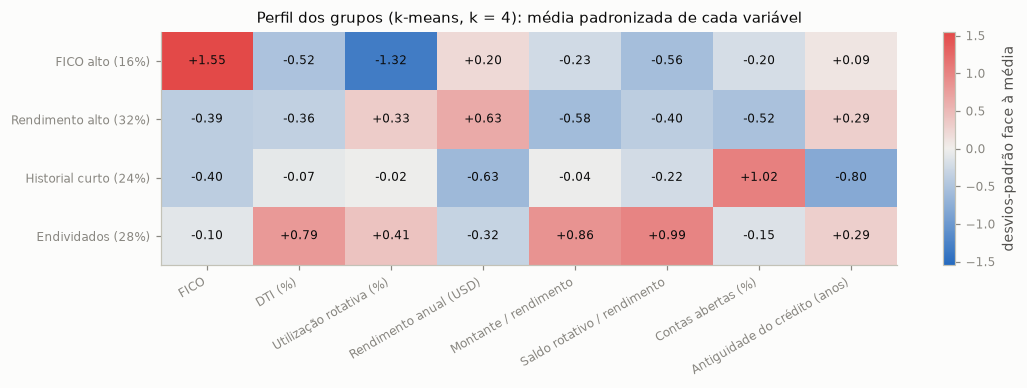

In [18]:
z = X.groupby(group.to_numpy()).mean().reindex(GROUP_ORDER).rename(columns=PROFILE_LABELS)
limit = np.abs(z.to_numpy()).max()

fig, ax = plt.subplots(figsize=(10, 3.6))
image = ax.imshow(z, cmap=DIVERGING_CMAP, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(z.shape[1]), z.columns, rotation=30, ha="right")
ax.set_yticks(range(len(z)), [f"{name} ({profile.loc[name, '% dos empréstimos']:.0f}%)" for name in z.index])
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(image, ax=ax, label="desvios-padrão face à média")
ax.set_title("Perfil dos grupos (k-means, k = 4): média padronizada de cada variável")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_perfis.png")
plt.show()

Variância explicada: PC1 25.3%, PC2 18.6% (total 43.9%)


,PC1,PC2
FICO,-0.28,-0.08
DTI (%),0.46,0.11
Utilização rotativa (%),0.37,0.34
Rendimento anual (USD),-0.34,0.47
Montante / rendimento,0.43,-0.09
Saldo rotativo / rendimento,0.49,0.22
Contas abertas (%),0.15,-0.50
Antiguidade do crédito (anos),-0.05,0.58


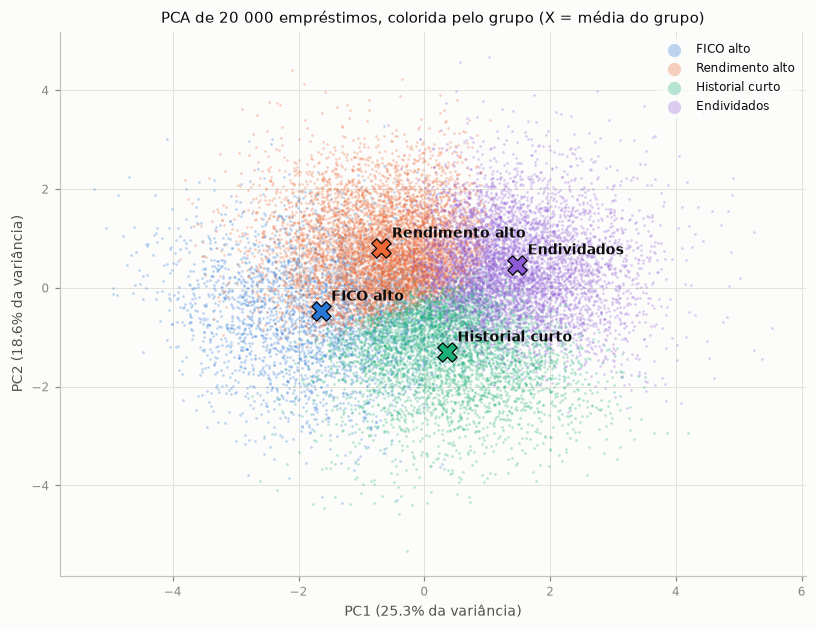

In [19]:
pca = PCA(n_components=2, random_state=config.RANDOM_SEED).fit(Xn)
explained = 100 * pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=[PROFILE_LABELS[c] for c in profiles.features],
                        columns=["PC1", "PC2"])
print(f"Variância explicada: PC1 {explained[0]:.1f}%, PC2 {explained[1]:.1f}% (total {explained.sum():.1f}%)")
display(loadings.round(2))

sample = np.sort(np.random.default_rng(config.RANDOM_SEED).choice(len(Xn), 20_000, replace=False))
coords = pca.transform(Xn[sample])
centers = pca.transform(X.groupby(group.to_numpy()).mean().reindex(GROUP_ORDER).to_numpy())
sample_group = group.to_numpy()[sample]

fig, ax = plt.subplots(figsize=(7.5, 5.8))
for name in GROUP_ORDER:
    mask = sample_group == name
    ax.scatter(coords[mask, 0], coords[mask, 1], s=3, alpha=0.3, color=GROUP_COLORS[name], label=name,
               rasterized=True)
for name, (x, y) in zip(GROUP_ORDER, centers):
    ax.scatter(x, y, s=160, marker="X", color=GROUP_COLORS[name], edgecolor="black", linewidth=0.8, zorder=3)
    ax.annotate(name, (x, y), xytext=(7, 7), textcoords="offset points", fontsize=9, weight="bold")
ax.set_xlabel(f"PC1 ({explained[0]:.1f}% da variância)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}% da variância)")
ax.legend(markerscale=5, loc="upper right")
ax.set_title("PCA de 20 000 empréstimos, colorida pelo grupo (X = média do grupo)")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_pca.png")
plt.show()

**Leitura.**

**Os quatro grupos** (medianas; entre parênteses, a média padronizada do mapa de calor):

| Grupo | Peso | O que o distingue | Fora do ajuste |
|---|---|---|---|
| **FICO alto** | 16% (75 367) | FICO 740 (+1,55), utilização rotativa de 24% (-1,32), DTI 12,6% (-0,52), pouco saldo rotativo face ao rendimento | 33% já tiveram atrasos e 7% têm registo público (todos: 46% e 13%) |
| **Rendimento alto** | 32% (151 361) | Rendimento de 85 000 USD (+0,63), montante pequeno face ao rendimento (0,15; -0,58), menos contas abertas (38%), historial longo (16,6 anos) | **64% já tiveram atrasos** e 19% têm registo público, os valores mais altos; FICO 680 (-0,39) |
| **Historial curto** | 24% (111 185) | Historial de crédito de 9,6 anos (-0,80), 65% das contas ainda abertas (+1,02), rendimento de 46 000 USD (-0,63) | 37% e 14%, perto da média |
| **Endividados** | 28% (128 211) | Saldo rotativo de 0,37 vezes o rendimento (+0,99), montante de 0,32 do rendimento (+0,86), DTI 23,5% (+0,79), utilização de 67% | 42% e 9% |

- **Os grupos têm leitura de negócio.** "FICO alto" são os mutuários *prime* que quase não usam o crédito que têm. "Endividados" pedem muito face ao que ganham e já devem muito. "Historial curto" são mutuários novos no crédito, com rendimentos mais baixos e contas recentes. "Rendimento alto" ganha bem e pede pouco face ao rendimento, mas é o grupo com mais atrasos passados e registos públicos.
- **As binárias que ficaram fora do ajuste diferem entre grupos** (33% a 64% com atrasos). Os grupos captam mais do que as 8 variáveis usadas: o historial de atrasos acompanha o FICO (que o inclui no cálculo), e o grupo com FICO mais baixo e historial mais longo é o que acumulou mais incidentes.
- **A PCA mostra dois eixos.**
  - PC1 (25% da variância) é o **endividamento face ao rendimento**: pesos positivos no saldo rotativo / rendimento (0,49), DTI (0,46), montante / rendimento (0,43) e utilização (0,37); negativos no rendimento (-0,34) e no FICO (-0,28).
  - PC2 (19%) é a **maturidade do crédito**: antiguidade (0,58) e rendimento (0,47) contra contas abertas (-0,50).
  - Os centros dos grupos ocupam as quatro direções deste plano: "FICO alto" à esquerda (pouco endividamento), "Endividados" à direita, "Rendimento alto" em cima (historial longo) e "Historial curto" em baixo.
- **Os pontos dos grupos sobrepõem-se na projeção.** A nuvem é uma só, sem ilhas, coerente com a silhueta de 0,14. Além disso, as duas componentes só mostram 44% da variância: os grupos separam-se melhor nas 8 dimensões do que neste plano. O k-means corta a nuvem contínua em quatro regiões, e cada uma corresponde a um tipo de mutuário reconhecível.

O passo seguinte dá significado de risco a cada grupo: a taxa de juro e a taxa de *default*, calculadas depois do ajuste.

## 7. Risco dos grupos: taxa de juro e *default*

Os grupos foram formados só com o perfil do mutuário no pedido. Agora, com os grupos fixos, junta-se o que a LendingClub decidiu e o que aconteceu depois, para dar significado de negócio aos grupos. Nada disto entrou no ajuste:

- **Taxa de juro e grau:** como a LendingClub avaliou e cobrou o risco de cada grupo. Existem para todos os empréstimos (são fixados na concessão).
- **Taxa de *default*:** o que aconteceu de facto. É calculada **só nos empréstimos com o desfecho observável** (`outcome_observed`), com a regra de observabilidade da classificação: o prazo tem de terminar até ao corte comum de 31/12/2018. Entram todos os empréstimos de 36 meses e os de 60 meses concedidos até 2013-12. Ficam de fora os de 60 meses de 2014: desses, só teriam terminado os que pagaram ou falharam cedo (*follow-up* desigual), e a taxa ficaria enviesada. O alvo é o da classificação (Charged Off e Default; os *At risk* depois do fim do prazo contam como Default).
- **Intervalo de confiança de 95%** (Wilson) em cada taxa de *default*.

Os grupos têm misturas de anos diferentes (secção 5), e a taxa de *default* também mudou de ano para ano. Por isso, a seguir compara-se também a taxa de cada grupo **dentro de cada ano de concessão**, para ver se as diferenças são dos grupos ou dos anos.

In [20]:
observed = outcome_observed(data)
print(f"Empréstimos com desfecho observável: {observed.sum():,} de {len(data):,} ({100 * observed.mean():.1f}%)")

outcomes = pd.concat([group_outcomes(data, group).reindex(GROUP_ORDER),
                      group_outcomes(data, np.full(len(data), "todos"))])
grades = 100 * pd.crosstab(group.rename("grupo"), data["grade"], normalize="index").reindex(GROUP_ORDER)
grades.loc["todos"] = 100 * data["grade"].value_counts(normalize=True).reindex(grades.columns)
grades.columns = [f"grau {g} (%)" for g in grades.columns]

# Tabela final dos grupos: perfil (secção 6) + risco + graus
groups_table = profile.join(outcomes.drop(columns="empréstimos")).join(grades)
groups_table.index.name = "grupo"
groups_table.to_csv(RESULTS_DIR / "clustering_groups.csv")

display(outcomes.round(2))
grades.round(1)

Empréstimos com desfecho observável: 393,131 de 466,124 (84.3%)


,empréstimos,juro médio (%),juro mediano (%),60 meses (%),com desfecho,defaults,default (%),IC 95% inferior,IC 95% superior
grupo,,,,,,,,,
FICO alto,75367,10.20,9.17,23.09,67153,5802,8.64,8.43,8.85
Rendimento alto,151361,14.06,13.68,25.13,128851,16268,12.63,12.45,12.81
Historial curto,111185,14.71,14.33,18.23,99631,17764,17.83,17.59,18.07
Endividados,128211,14.92,14.49,40.96,97496,18578,19.06,18.81,19.30
todos,466124,13.83,13.66,27.51,393131,58412,14.86,14.75,14.97


,grau A (%),grau B (%),grau C (%),grau D (%),grau E (%),grau F (%),grau G (%)
grupo,,,,,,,
FICO alto,49.6,29.5,13.0,5.1,1.9,0.7,0.1
Rendimento alto,11.9,31.9,28.7,16.6,7.4,2.8,0.8
Historial curto,6.9,29.6,30.8,20.2,8.5,3.2,0.8
Endividados,9.1,26.1,29.4,19.9,10.7,3.9,0.9
todos,16.1,29.4,26.9,16.5,7.7,2.8,0.7


In [21]:
# Taxa de default de cada grupo dentro de cada ano de concessão (só desfecho observável)
years_observed = sorted(data.loc[observed, "issue_d"].dt.year.unique())
by_year = pd.DataFrame({y: group_outcomes(data[year == y], group[year == y])["default (%)"]
                        for y in years_observed}).reindex(GROUP_ORDER)
by_year.loc["todos"] = [group_outcomes(data[year == y], np.full((year == y).sum(), "todos"))["default (%)"].iloc[0]
                        for y in years_observed]
by_year.columns.name = "ano de concessão"
display(by_year.round(1))

# Robustez: os grupos do GMM diag (emparelhados com os do k-means) têm o mesmo risco?
diag_group = pd.Series(match_labels(km4, diag4), index=data.index).map(GROUP_NAMES)
pd.DataFrame({"k-means: default (%)": outcomes["default (%)"].reindex(GROUP_ORDER),
              "GMM diag: default (%)": group_outcomes(data, diag_group)["default (%)"].reindex(GROUP_ORDER),
              "k-means: juro médio (%)": outcomes["juro médio (%)"].reindex(GROUP_ORDER),
              "GMM diag: juro médio (%)": group_outcomes(data, diag_group)["juro médio (%)"].reindex(GROUP_ORDER)}).round(2)

ano de concessão,2007,2008,2009,2010,2011,2012,2013,2014
grupo,,,,,,,,
FICO alto,16.2,13.4,8.9,9.1,9.5,9.9,8.8,7.4
Rendimento alto,27.2,25.6,14.4,15.4,15.1,13.8,12.8,11.6
Historial curto,29.1,19.3,16.8,17.1,18.7,18.3,17.9,17.5
Endividados,33.3,29.0,18.8,18.3,21.9,21.1,20.1,16.9
todos,26.2,20.8,13.7,14.0,15.2,16.2,15.6,13.7


,k-means: default (%),GMM diag: default (%),k-means: juro médio (%),GMM diag: juro médio (%)
grupo,,,,
FICO alto,8.64,10.08,10.20,11.09
Rendimento alto,12.63,11.99,14.06,13.75
Historial curto,17.83,19.45,14.71,15.34
Endividados,19.06,15.98,14.92,13.97


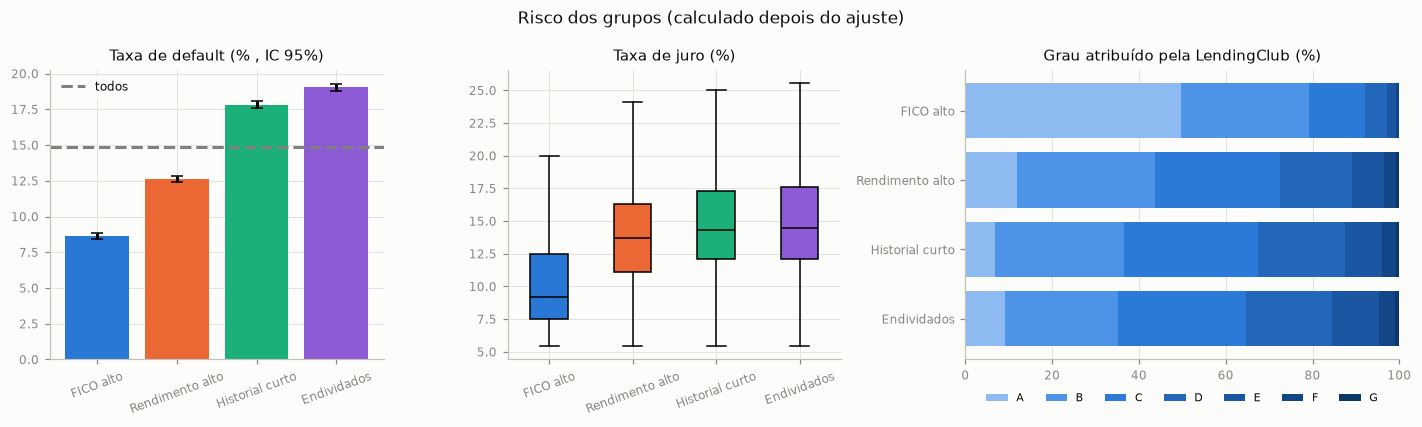

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.3]})
colors = [GROUP_COLORS[name] for name in GROUP_ORDER]
rows = outcomes.loc[GROUP_ORDER]

ax = axes[0]
errors = [rows["default (%)"] - rows["IC 95% inferior"], rows["IC 95% superior"] - rows["default (%)"]]
ax.bar(GROUP_ORDER, rows["default (%)"], yerr=errors, color=colors, capsize=4)
ax.axhline(outcomes.loc["todos", "default (%)"], color="grey", linestyle="--", label="todos")
ax.set_title("Taxa de default (% , IC 95%)")
ax.legend()

ax = axes[1]
parts = ax.boxplot([data.loc[group == name, "int_rate"] for name in GROUP_ORDER], tick_labels=GROUP_ORDER,
                   showfliers=False, patch_artist=True, medianprops={"color": "black"})
for patch, color in zip(parts["boxes"], colors):
    patch.set_facecolor(color)
ax.set_title("Taxa de juro (%)")

ax = axes[2]
grade_shares = grades.loc[GROUP_ORDER]
left = np.zeros(len(GROUP_ORDER))
shades = SEQUENTIAL_CMAP(np.linspace(0.15, 1, grade_shares.shape[1]))
for column, shade in zip(grade_shares.columns, shades):
    ax.barh(GROUP_ORDER, grade_shares[column], left=left, color=shade, label=column.split()[1])
    left += grade_shares[column].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("Grau atribuído pela LendingClub (%)")
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False, fontsize=7)
for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Risco dos grupos (calculado depois do ajuste)")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "mod_clu_risco.png")
plt.show()

**Leitura.**

- **O risco ordena os grupos de forma clara.** A taxa de *default* (393 131 empréstimos com desfecho observável, 84%) vai de **8,6% no grupo "FICO alto"** a 12,6% em "Rendimento alto", 17,8% em "Historial curto" e **19,1% em "Endividados"** (todos: 14,9%). O pior grupo tem 2,2 vezes o *default* do melhor. Com mais de 67 000 empréstimos por grupo, os intervalos de 95% têm cerca de ±0,2 p.p., e nenhum se sobrepõe a outro.
- **A ordem não vem da mistura de anos.** Dentro de cada ano de 2009 a 2014, "FICO alto" tem sempre o menor *default* (7,4% a 9,9%) e "Rendimento alto" o segundo menor (11,6% a 15,4%). "Historial curto" e "Endividados" são sempre os dois de maior risco (16,8% a 21,9%), mas a ordem entre eles troca em 2014. Em 2007-2008, o *default* é alto em todos os grupos (crise financeira), e a ordem dos três grupos não-*prime* muda (são poucos empréstimos: 603 em 2007).
- **O GMM `diag` confirma a leitura principal.** "FICO alto" (10,1%) e "Rendimento alto" (12,0%) são os de menor risco, e os outros dois os de maior risco. Também aqui a ordem entre "Historial curto" (19,5%) e "Endividados" (16,0%) troca: estes dois grupos têm um risco parecido, e a fronteira entre eles depende do algoritmo.
- **A LendingClub cobrou o risco, mas só em parte.** "FICO alto" tem metade dos empréstimos no grau A e um juro médio de 10,2%, contra 13,8% em todos. Os três outros grupos têm juros quase iguais (14,1% a 14,9%) e graus parecidos (sobretudo B a D), mas o *default* vai de 12,6% a 19,1%. O perfil do mutuário parece ter informação de risco que o grau não captou toda, o que é coerente com a classificação (o rendimento e os pedidos de crédito recentes contam além da taxa de juro). Atenção: esta comparação não ajusta o prazo nem o montante. "Endividados" tem 41% de empréstimos a 60 meses, contra 18% em "Historial curto", e os de 60 meses têm juros e *default* mais altos.
- **Ter tido atrasos não basta para ter mais risco.** "Rendimento alto" é o grupo com mais atrasos no passado (64%) e mais registos públicos (19%), mas tem o segundo menor *default*. O rendimento alto e o pouco esforço do empréstimo pesam mais do que o historial de incidentes.

**Limitações para o relatório:**
- *Selection bias*: só há empréstimos **aceites**. Os grupos descrevem a carteira da LendingClub, não todos os candidatos; os rejeitados podem ter perfis (e riscos) que aqui não aparecem.
- *Follow-up* desigual: tratado com a regra de observabilidade. A taxa usa 84% dos empréstimos, e os de 60 meses de 2014 ficam de fora.
- Associação, não causalidade: os grupos descrevem quem falhou mais. Não dizem que mudar o perfil mudaria o risco.
- Fairness: as variáveis do ajuste não incluem atributos protegidos nem a geografia, mas o rendimento e a antiguidade do crédito podem estar ligados à idade e à condição socioeconómica. Usar os grupos para decidir crédito pediria esta análise.